First 5 Records:
   Transaction ID        Date Product Category             Product Name  \
0           10001  2024-01-01      Electronics            iPhone 14 Pro   
1           10002  2024-01-02  Home Appliances         Dyson V11 Vacuum   
2           10003  2024-01-03         Clothing         Levi's 501 Jeans   
3           10004  2024-01-04            Books        The Da Vinci Code   
4           10005  2024-01-05  Beauty Products  Neutrogena Skincare Set   

   Units Sold  Unit Price  Total Revenue         Region Payment Method  
0           2      999.99        1999.98  North America    Credit Card  
1           1      499.99         499.99         Europe         PayPal  
2           3       69.99         209.97           Asia     Debit Card  
3           4       15.99          63.96  North America    Credit Card  
4           1       89.99          89.99         Europe         PayPal  

Dataset Shape:
(240, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Product Category', '

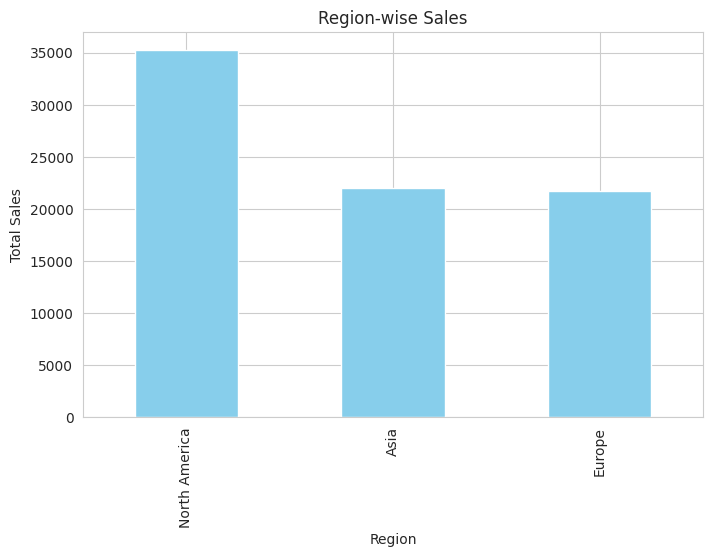

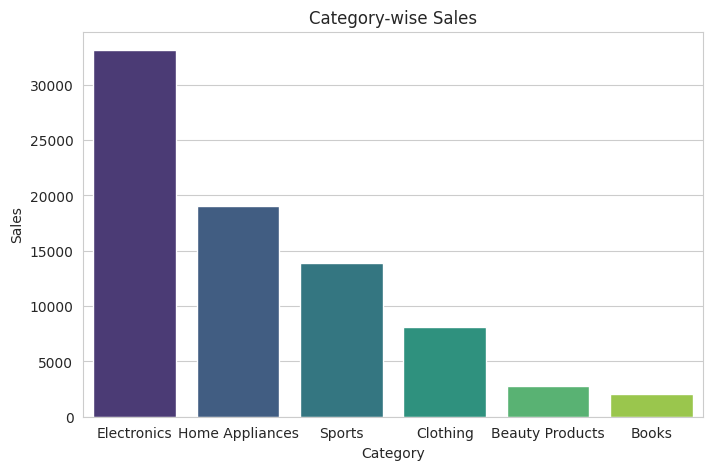

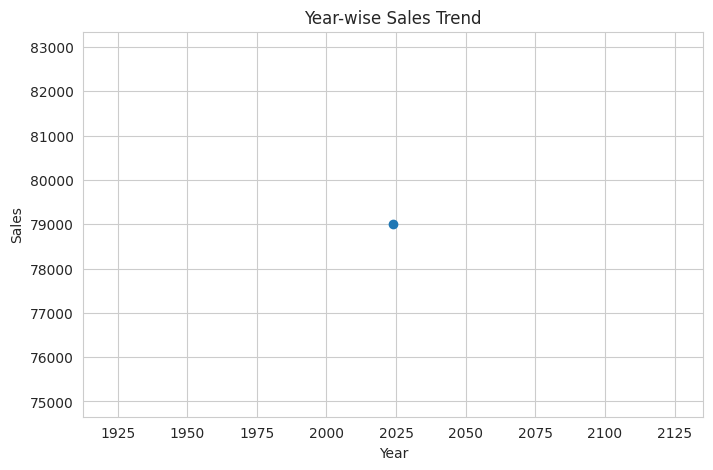

In [4]:
# ==========================================================
# MILESTONE 1 - CIE
# Data Transformation, Null Value Handling,
# Insight Generation and Visualization
# Dataset: Superstore Sales Dataset
# ==========================================================

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

# ==========================================================
# 1. DATASET SELECTION AND READING
# ==========================================================

# Read Dataset
df = pd.read_csv("sales_data.csv", encoding='latin1')

print("First 5 Records:")
print(df.head())

# ==========================================================
# 2. DATA UNDERSTANDING
# ==========================================================

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values Before Handling:")
print(df.isnull().sum())

# ==========================================================
# 3. DATA TRANSFORMATION
# ==========================================================

# Convert date columns to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Create additional columns
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()

# Drop unnecessary column
if 'Row ID' in df.columns:
    df.drop('Row ID', axis=1, inplace=True)

print("\nData After Transformation:")
print(df.head())

# ==========================================================
# 4. HANDLING NULL VALUES USING MEAN IMPUTATION
# ==========================================================

# (Optional) Introduce missing values for demonstration
df.loc[10:20, 'Total Revenue'] = np.nan

print("\nMissing Values After Introducing Nulls:")
print(df.isnull().sum())

# Mean Imputation (Warning Avoided: Assigning directly to df[col] instead of inplace)
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

print("\nMissing Values After Mean Imputation:")
print(df.isnull().sum())

# ==========================================================
# 5. INSIGHT GENERATION
# ==========================================================

# Region-wise Sales
region_sales = df.groupby('Region')['Total Revenue'].sum().sort_values(ascending=False)

# Category-wise Sales
category_sales = df.groupby('Product Category')['Total Revenue'].sum().sort_values(ascending=False)

# Year-wise Sales Trend
year_sales = df.groupby('Year')['Total Revenue'].sum()

# Top 10 Profitable Products
top_products = (
    df.groupby('Product Name')['Total Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nRegion-wise Sales:")
print(region_sales)

print("\nCategory-wise Sales:")
print(category_sales)

print("\nYear-wise Sales:")
print(year_sales)

print("\nTop 10 High-Revenue Products:")
print(top_products)

# ==========================================================
# 6. DATA VISUALIZATION
# ==========================================================

# Visualization 1: Region-wise Sales
plt.figure(figsize=(8,5))
region_sales.plot(kind='bar', color='skyblue')
plt.title('Region-wise Sales')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

# Visualization 2: Category-wise Sales
plt.figure(figsize=(8,5))
sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    hue=category_sales.index,
    palette='viridis',
    legend=False
)
plt.title('Category-wise Sales')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.show()

# Visualization 3: Year-wise Sales Trend
plt.figure(figsize=(8,5))
plt.plot(
    year_sales.index,
    year_sales.values,
    marker='o',
    linewidth=3
)
plt.title('Year-wise Sales Trend')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.grid(True)
plt.show()
